# Loyers à Montréal, 1992-2026 : l'analyse pas à pas en Python

Ce notebook reproduit les constats du site à partir des tables propres produites par `src/pipeline.py`, puis pose deux questions de plus, utiles à un gestionnaire immobilier : **combien rapporte une relocation**, et **où l'écart entre loyer affiché et loyer payé est-il le plus grand au Canada**. Il se termine par une **réconciliation** : chaque chiffre recalculé ici est comparé à celui publié sur le site.

*This notebook reproduces the site's findings with pandas, adds two real-estate questions (what a re-let earns, where the asking/paid gap is widest in Canada) and ends with a reconciliation against the published figures.*

Sources : Statistique Canada, tableaux 34-10-0133-01 (loyers SCHL), 34-10-0127-01 (inoccupation), 18-10-0005-01 (IPC), 46-10-0092-01 (loyers demandés et payés) ; SCHL, Rapport sur le marché locatif 2025. Licence du gouvernement ouvert – Canada.

In [1]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt

# En local, les tables sont dans ../data/clean ; dans Google Colab, elles sont lues depuis le dépôt GitHub.
LOCAL = "../data/clean/"
REMOTE = "https://raw.githubusercontent.com/sashamartenon-jpg/Montreal-Rents-Who-Really-Pays-the-Increase-/main/data/clean/"   # remplace sashamartenon-jpg
BASE = LOCAL if os.path.exists(LOCAL + "fait_loyers_montreal.csv") else REMOTE

loyers = pd.read_csv(BASE + "fait_loyers_montreal.csv")      # Montréal, 4 types de logement, 1992-2025
villes = pd.read_csv(BASE + "fait_loyers_2ch_rmr.csv")       # 2 chambres, 6 grandes villes
inocc  = pd.read_csv(BASE + "fait_inoccupation.csv")         # taux d'inoccupation, 6 villes
ipc    = pd.read_csv(BASE + "ipc_montreal.csv")              # IPC Montréal
roul   = pd.read_csv(BASE + "schl_roulement.csv")            # SCHL : logements reloués, 2022-2025
trim   = pd.read_csv(BASE + "fait_loyer_trimestriel.csv")    # loyers demandés (A) et payés (P), 42 régions, trimestriel
rmr    = pd.read_csv(BASE + "dim_rmr.csv")                   # noms des 42 régions

pd.options.display.float_format = "{:,.1f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLEU, ORANGE, GRIS = "#2a78d6", "#eb6834", "#9aa5b5"
print(f"Source des tables : {BASE}")
loyers.tail(4)

Source des tables : ../data/clean/


,year,unit_id,loyer_nominal,geo_id,loyer_reel_2025,var_annuelle_pct
132,2022,studio,785,Montreal,870.0,10.3
133,2023,studio,809,Montreal,853.0,3.1
134,2024,studio,892,Montreal,915.0,10.3
135,2025,studio,1005,Montreal,"1,005.0",12.7


## 1. La hausse réelle d'un 2 chambres : 1992-2019 contre 2019-2025

Le loyer réel est le loyer d'octobre converti en dollars de 2025 avec l'IPC de Montréal. Comparer deux périodes de longueurs différentes demande un **rythme annuel** (taux de croissance annuel composé), pas une hausse totale.

In [2]:
deux = loyers[loyers.unit_id == "2ch"].set_index("year")
reel = deux.loyer_reel_2025

def hausse(a, b):
    return reel[b] / reel[a] - 1

def rythme(a, b):
    return (reel[b] / reel[a]) ** (1 / (b - a)) - 1

resume = pd.DataFrame({
    "période": ["1992-2019", "2019-2025"],
    "hausse réelle": [hausse(1992, 2019), hausse(2019, 2025)],
    "rythme annuel": [rythme(1992, 2019), rythme(2019, 2025)],
}).set_index("période")
resume.style.format({"hausse réelle": "{:+.1%}", "rythme annuel": "{:+.2%}"})

,hausse réelle,rythme annuel
période,,
1992-2019,+14.3%,+0.49%
2019-2025,+27.2%,+4.09%


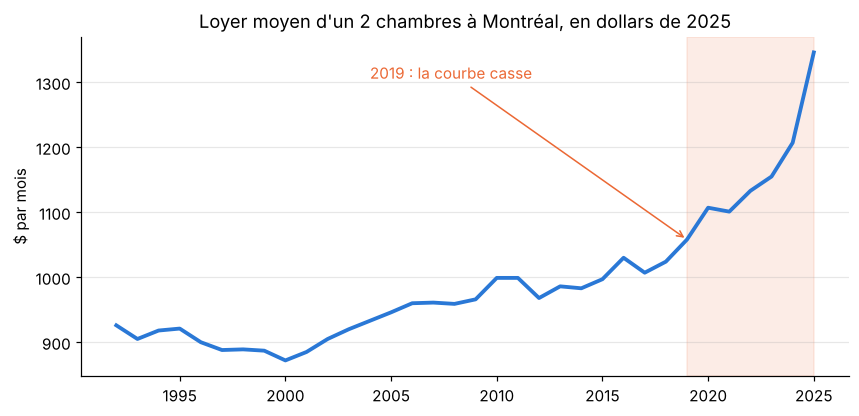

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(reel.index, reel.values, color=BLEU, lw=2.5)
ax.axvspan(2019, 2025, color=ORANGE, alpha=.12)
ax.annotate("2019 : la courbe casse", (2019, reel[2019]), xytext=(2004, reel.max() * .97), color=ORANGE,
            arrowprops=dict(arrowstyle="->", color=ORANGE))
ax.set_title("Loyer moyen d'un 2 chambres à Montréal, en dollars de 2025")
ax.set_ylabel("$ par mois"); ax.grid(axis="y", alpha=.3)
plt.show()

## 2. Montréal face aux cinq autres grandes villes

Un indice 2019 = 100 met les villes sur la même échelle quel que soit leur niveau de loyer.

,hausse 2019-2025
geo_id,
Montreal,+57.4%
Quebec,+48.1%
Calgary,+46.7%
Ottawa-Gatineau,+42.7%
Vancouver,+35.2%
Toronto,+31.0%


Montréal en % de Toronto : 59.0% en 2015 → 65.8% en 2025


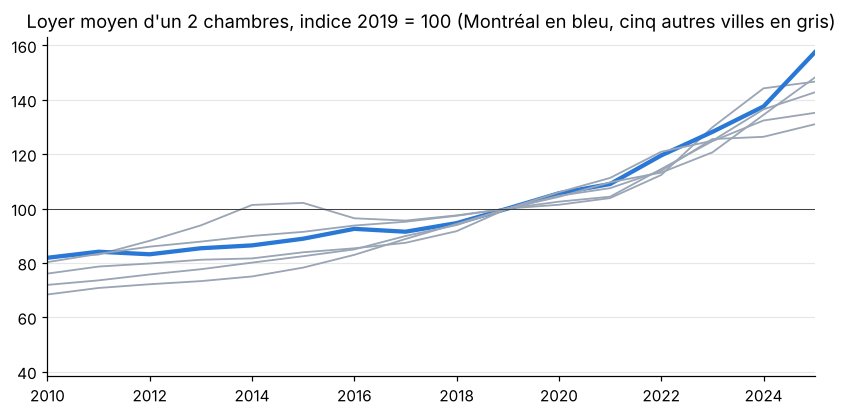

In [4]:
pv = villes.pivot(index="year", columns="geo_id", values="loyer_nominal")
comparaison = (pv.loc[2025] / pv.loc[2019] - 1).sort_values(ascending=False).rename("hausse 2019-2025")
display(comparaison.to_frame().style.format("{:+.1%}"))
print(f"Montréal en % de Toronto : {pv.loc[2015, 'Montreal'] / pv.loc[2015, 'Toronto']:.1%} en 2015 → {pv.loc[2025, 'Montreal'] / pv.loc[2025, 'Toronto']:.1%} en 2025")

idx = pv / pv.loc[2019] * 100
fig, ax = plt.subplots(figsize=(9, 4))
for g in idx.columns:
    ax.plot(idx.index, idx[g], color=BLEU if g == "Montreal" else GRIS, lw=2.8 if g == "Montreal" else 1.2, label=g if g == "Montreal" else None)
ax.axhline(100, color="#333", lw=.6); ax.set_xlim(2010, 2025)
ax.set_title("Loyer moyen d'un 2 chambres, indice 2019 = 100 (Montréal en bleu, cinq autres villes en gris)")
ax.grid(axis="y", alpha=.3); plt.show()

## 3. Inoccupation et hausse de loyer : quelle relation ?

La théorie veut que plus de logements libres freine les loyers. Sur 28 années montréalaises, la relation existe mais elle est faible, et 2025 sort du nuage : plus de logements libres **et** la plus forte hausse depuis 1992.

Corrélation 1998-2025 : -0.16  (n = 28)


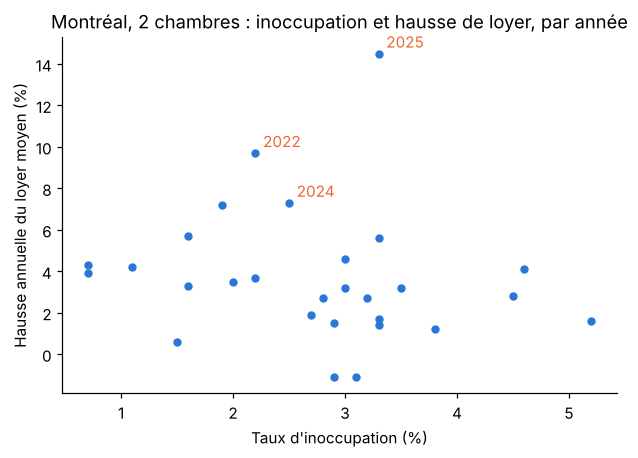

In [5]:
m = (inocc[inocc.geo_id == "Montreal"].set_index("year").taux_inoccupation_pct
     .to_frame("inoccupation").join(deux.var_annuelle_pct.rename("hausse")).dropna())
corr = m.inoccupation.corr(m.hausse)
print(f"Corrélation {m.index.min()}-{m.index.max()} : {corr:.2f}  (n = {len(m)})")
ax = m.plot.scatter(x="inoccupation", y="hausse", figsize=(6.5, 4.2), color=BLEU)
for y in (2022, 2024, 2025):
    ax.annotate(str(y), (m.loc[y, "inoccupation"], m.loc[y, "hausse"]), xytext=(5, 4), textcoords="offset points", color=ORANGE)
ax.set_xlabel("Taux d'inoccupation (%)"); ax.set_ylabel("Hausse annuelle du loyer moyen (%)")
ax.set_title("Montréal, 2 chambres : inoccupation et hausse de loyer, par année"); plt.show()

## 4. Immobilier : combien rapporte une relocation ?

La SCHL publie, pour les 2 chambres, le loyer des logements **reloués à un nouveau locataire**. L'écart avec le loyer moyen de tous les locataires est le revenu supplémentaire qu'un départ libère. C'est aussi la mesure du marché qu'un gestionnaire devrait regarder avant de fixer un loyer, plutôt que la moyenne.

,"loyer moyen, tous locataires ($)",loyer des logements reloués ($),écart mensuel ($),écart (%),revenu annuel libéré par une relocation ($)
year,,,,,
2022,1022,1235.000000,213.000000,20.8 %,2556.000000
2023,1096,1310.000000,214.000000,19.5 %,2568.000000
2024,1176,1407.000000,231.000000,19.6 %,2772.000000
2025,1346,1644.000000,298.000000,22.1 %,3576.000000


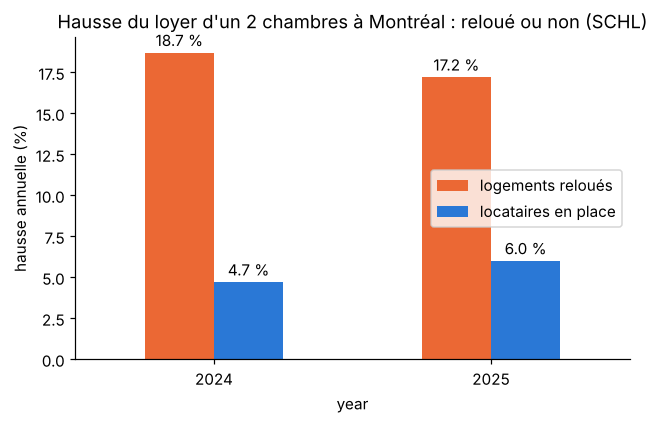

In [6]:
r = roul.pivot(index="year", columns="indicateur", values="valeur")
moy = deux.loyer_nominal
gain = pd.DataFrame({
    "loyer moyen, tous locataires ($)": moy.loc[r.index],
    "loyer des logements reloués ($)": r.loyer_moyen_reloues_2ch,
})
gain["écart mensuel ($)"] = gain.iloc[:, 1] - gain.iloc[:, 0]
gain["écart (%)"] = gain["écart mensuel ($)"] / gain.iloc[:, 0] * 100
gain["revenu annuel libéré par une relocation ($)"] = gain["écart mensuel ($)"] * 12
display(gain.style.format("{:,.0f}").format({"écart (%)": "{:.1f} %"}))

h = r[["hausse_loyer_reloues_2ch", "hausse_loyer_non_reloues_2ch"]].dropna()
h.columns = ["logements reloués", "locataires en place"]
ax = h.plot.bar(figsize=(6.5, 3.8), color=[ORANGE, BLEU], rot=0)
ax.set_ylabel("hausse annuelle (%)"); ax.set_title("Hausse du loyer d'un 2 chambres à Montréal : reloué ou non (SCHL)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f %%", padding=2)
plt.show()

## 5. Immobilier : où l'écart affiché / payé est-il le plus grand au Canada ?

Statistique Canada publie depuis 2025, chaque trimestre et pour 42 régions métropolitaines, le **loyer demandé** dans les annonces (estimation A) et le **loyer payé** par les locataires en place (estimation P). Le loyer payé n'est publié que pour 16 régions. L'écart en pourcentage dit, région par région, combien un déménagement coûte de plus que rester.

Période : 2026 T2 · 16 régions avec loyer payé publié


,loyer demandé ($),loyer payé ($),nom,province,écart ($),écart (%)
1,"1,940","1,400",Grand Sudbury,ON,540,38.6 %
2,"2,400","1,770",Halifax,NS,630,35.6 %
3,"1,300",960,Sherbrooke,QC,340,35.4 %
4,"1,820","1,360",Montréal,QC,460,33.8 %
5,"1,700","1,370","Gatineau (Ottawa-Gatineau, partie québécoise)",QC,330,24.1 %
6,"2,120","1,720",Kitchener - Cambridge - Waterloo,ON,400,23.3 %
7,"1,920","1,560",London,ON,360,23.1 %
8,"2,650","2,160",Toronto,ON,490,22.7 %
9,"3,030","2,470",Vancouver,BC,560,22.7 %
10,"1,460","1,230",Québec,QC,230,18.7 %


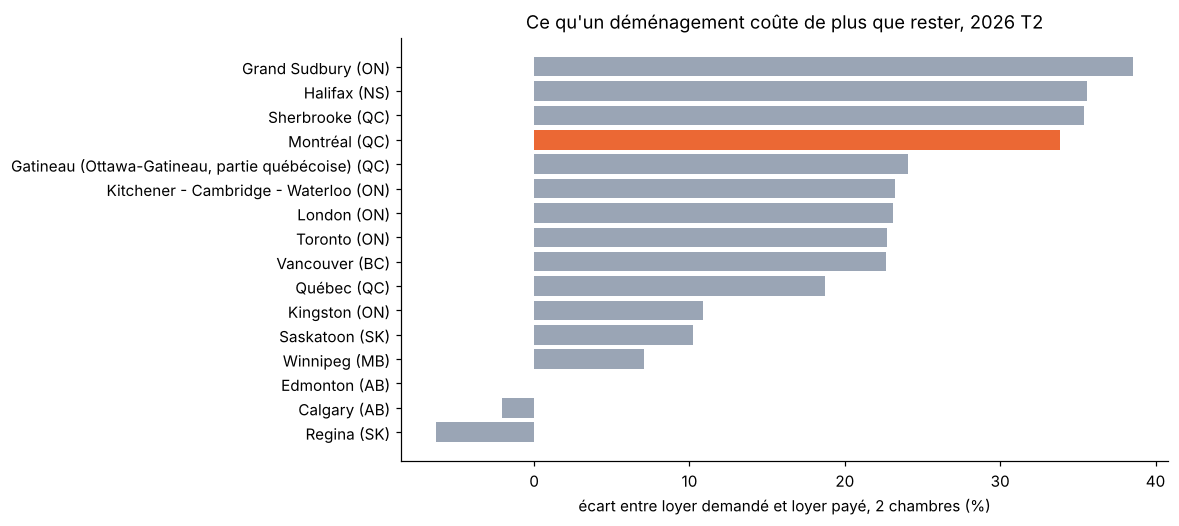

In [7]:
dernier = trim.periode.max()
lib = f"{dernier[:4]} T{(int(dernier[5:]) - 1) // 3 + 1}"   # 2026-04 → 2026 T2
t = trim[trim.periode == dernier].pivot(index="geo_id", columns="estimation", values="loyer").dropna()
t = t.join(rmr.set_index("geo_id")[["nom", "province"]])
t["écart ($)"] = t.A - t.P
t["écart (%)"] = t["écart ($)"] / t.P * 100
t = t.sort_values("écart (%)", ascending=False).reset_index(drop=True)
t.index += 1
print(f"Période : {lib} · {len(t)} régions avec loyer payé publié")
display(t.rename(columns={"A": "loyer demandé ($)", "P": "loyer payé ($)"})
         .style.format({"loyer demandé ($)": "{:,.0f}", "loyer payé ($)": "{:,.0f}", "écart ($)": "{:,.0f}", "écart (%)": "{:.1f} %"}))

fig, ax = plt.subplots(figsize=(9, 5))
cols = [ORANGE if n == "Montréal" else GRIS for n in t.nom]
ax.barh(t.nom + " (" + t.province + ")", t["écart (%)"], color=cols)
ax.invert_yaxis(); ax.set_xlabel("écart entre loyer demandé et loyer payé, 2 chambres (%)")
ax.set_title(f"Ce qu'un déménagement coûte de plus que rester, {lib}")
plt.show()

## 6. Qualité des données et réconciliation avec le site

Deux réflexes d'intelligence d'affaires avant de publier un chiffre : **lire les indicateurs de qualité de la source** (Statistique Canada signale les estimations à utiliser avec prudence, cote E, et supprime celles qui sont trop peu fiables, cote F), puis **réconcilier** les résultats avec ce qui est déjà publié. Si un chiffre recalculé ici s'écartait du site, l'un des deux serait faux.

In [8]:
q = trim.assign(cote=trim.cote.fillna("publiée")).replace({"cote": {"E": "E · à utiliser avec prudence", "F": "F · trop peu fiable, supprimée", "..": ".. · non disponible"}})
qualite = q.pivot_table(index="periode", columns=["estimation", "cote"], values="geo_id", aggfunc="count", fill_value=0)
display(qualite)

# Réconciliation : chiffres recalculés ici contre ceux publiés sur le site (docs/data/data.json)
site_local = "../docs/data/data.json"
site = json.load(open(site_local)) if os.path.exists(site_local) else None
if site is None:
    import urllib.request
    site = json.load(urllib.request.urlopen(REMOTE.replace("data/clean/", "docs/data/data.json")))
K = site["insights"]
mtl = t[t.nom == "Montréal"].iloc[0]
checks = pd.DataFrame([
    ["hausse réelle 2019-2025 (%)",            round(hausse(2019, 2025) * 100, 1), K["hausse_reelle_2019_2025"]],
    ["hausse réelle 1992-2019 (%)",            round(hausse(1992, 2019) * 100, 1), K["hausse_reelle_1992_2019"]],
    ["loyer reloué 2025 ($)",                  r.loc[2025, "loyer_moyen_reloues_2ch"], K["loyer_reloues_2ch_2025"]],
    ["écart reloué / moyen 2025 ($)",          gain.loc[2025, "écart mensuel ($)"], K["prime_relocation_2025"]],
    ["hausse 2025, reloués (%)",               r.loc[2025, "hausse_loyer_reloues_2ch"], K["hausse_reloues_2025"]],
    ["hausse 2025, en place (%)",              r.loc[2025, "hausse_loyer_non_reloues_2ch"], K["hausse_non_reloues_2025"]],
    [f"Montréal, loyer demandé {lib} ($)", mtl.A, K["mtl_demande_dernier"]],
    [f"Montréal, loyer payé {lib} ($)",    mtl.P, K["mtl_paye_dernier"]],
    [f"Montréal, écart {lib} ($)",         mtl["écart ($)"], K["mtl_ecart_dernier"]],
], columns=["indicateur", "notebook", "site"]).set_index("indicateur")
checks["écart"] = (checks.notebook - checks.site).abs()
checks["verdict"] = checks["écart"].map(lambda e: "OK" if e < 0.051 else "ÉCART")
display(checks.style.format({"notebook": "{:,.1f}", "site": "{:,.1f}", "écart": "{:.2f}"}))
assert (checks.verdict == "OK").all(), "Un chiffre du notebook diffère du site : à investiguer avant toute publication."
print("Réconciliation réussie :", len(checks), "indicateurs identiques au site.")

estimation                   A                               \
cote       .. · non disponible E · à utiliser avec prudence   
periode                                                       
2025-04                      0                           37   
2025-07                      2                            5   
2025-10                      2                            2   
2026-01                      2                            1   
2026-04                      2                            0   

estimation                                         \
cote       F · trop peu fiable, supprimée publiée   
periode                                             
2025-04                                 4       0   
2025-07                                 0      36   
2025-10                                 0      39   
2026-01                                 0      40   
2026-04                                 0      41   

estimation                            P          
cote       E · à utiliser avec prudence publiée  
periode                                          
2025-04                               1      16  
2025-07                               2      15  
2025-10                               2      15  
2026-01                               2      15  
2026-04                               1      16

,notebook,site,écart,verdict
indicateur,,,,
hausse réelle 2019-2025 (%),27.2,27.2,0.00,OK
hausse réelle 1992-2019 (%),14.3,14.3,0.00,OK
loyer reloué 2025 ($),"1,644.0","1,644.0",0.00,OK
écart reloué / moyen 2025 ($),298.0,298.0,0.00,OK
"hausse 2025, reloués (%)",17.2,17.2,0.00,OK
"hausse 2025, en place (%)",6.0,6.0,0.00,OK
"Montréal, loyer demandé 2026 T2 ($)","1,820.0","1,820.0",0.00,OK
"Montréal, loyer payé 2026 T2 ($)","1,360.0","1,360.0",0.00,OK
"Montréal, écart 2026 T2 ($)",460.0,460.0,0.00,OK


Réconciliation réussie : 9 indicateurs identiques au site.


## Limites

- Le loyer moyen SCHL mélange locataires en place, logements qui changent de locataire et immeubles neufs ; la SCHL mesure à logement constant une hausse plus faible (7,2 % en 2025 contre 14,5 % pour la moyenne brute).
- Les loyers demandés et payés de Statistique Canada sont des **estimations expérimentales** ; le loyer payé n'existe que pour 16 régions sur 42.
- L'inoccupation (immeubles de 6 logements et plus) et le loyer (3 logements et plus) ne couvrent pas exactement le même parc.
- Une corrélation sur 28 points annuels ne prouve aucun lien de cause à effet ; le test de rupture complet (Chow, Monte Carlo) est dans `src/rupture.py`.